# GVH Diagonal Cubic — CHH-04
## `GVH_CHH_04_Heterogeneous_Aggregation_Benchmark_FAST`
### Combien de variables doivent survivre à l'agrégation ?

**Statut :** audit mathématique et numérique **complémentaire**, non canonique, sans nouvelle loi physique démontrée. Suite de CHH-01/02/03.

**Question :** la connaissance de la masse totale ou de quelques variables macroscopiques suffit-elle à déterminer l'évolution de ce cube hétérogène ? Tester (a) les lois de conservation, (b) l'existence d'une fermeture autonome, (c) la fidélité des prédictions pour des conditions initiales inédites.

**Architecture scientifique obligatoire**
1. **GVH :** la composition CHH est une proposition de description; ni l'opérateur d'agrégation ni les couplages ne sont dérivés de `S_cand`.
2. **Physique établie :** systèmes linéaires, équations de continuité, systèmes observés/réduits, condition de fermeture, intégration ODE.
3. **Test numérique minimal :** cas hétérogène construit **avant** comparaison, projection à 3/4/5 variables, intégrations indépendantes, témoins exacts de non-fermeture, plusieurs états initiaux tenus à l'écart de tout ajustement.
4. **Verdict :** PASS algébrique/numérique local ≠ validation d'une loi GVH. Quantités fictives sans échelle astrophysique. Les données ALMA ne sont pas ouvertes.

**Point de méthode :** un modèle fermé pour la **seule masse totale** peut être parfaitement exact (`dM/dt=0`) tout en étant incapable de prédire une observation dynamique (oscillation, circulation ou relaxation). L'identité de conservation ne représente pas une fermeture de l'ensemble des phénomènes.

## 1 — Sous-cubes hétérogènes et dynamique témoin

Un banc **linéaire synthétique** adimensionné a 6 variables d'état `x=(q,v,a,b,c,h)` :
- **A mécanique** : déplacement `q`, vitesse `v`, ressort amorti et couplages prescrits;
- **B matière** : trois masses de réservoirs `m_i=100+(a,b,c)` et flux dirigés `J_1=k m_1-εq`, `J_2=k m_2`, `J_3=k m_3`. La masse totale `M=m_1+m_2+m_3` est conservée, car `J` circule sur une boucle fermée;
- **C relaxation** : variable de réponse `h`, dont la dynamique est linéaire et dépend des autres composantes.

Le vecteur suit `ẋ=A x`; toutes les constantes de `A` sont **prescrites**, adimensionnées et sans prétention universelle. Les échanges entre mécanismes sont **toy**, non une force ou une énergie GVH. Aucune loi globale de conservation d'énergie n'est revendiquée pour ce banc, faute de secteur de travail/chaleur complet.

Les flux B sont effectivement représentés dans les EOM, et non seulement ajoutés à une observable. Les valeurs de base `100` servent à garantir des masses positives dans la plage de test; le système n'est pas une description quantitative du Soleil ni d'ALMA.

In [1]:
from pathlib import Path
import numpy as np, json, hashlib
from scipy.integrate import solve_ivp
from scipy.linalg import null_space
import matplotlib.pyplot as plt

NAME = "GVH_CHH_04_Heterogeneous_Aggregation_Benchmark_FAST"
DATA_ROOT=Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()
UPSTREAM_FROZEN={
  "GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_EXECUTED.ipynb": {
    "bytes": 100964,
    "sha256": "cb1608b3b60d71cdc12c3b496e0c9b909026d848a8074bc7eb0193cfe83f8bc0"
  },
  "GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_results.json": {
    "bytes": 3776,
    "sha256": "f43ef6b9a27e52ccc9c4d990232e31bd0ed5bc4afb3646d9e05775dc1682951e"
  },
  "GVH_CHH_02_Conservation_and_Aggregation_FAST_EXECUTED.ipynb": {
    "bytes": 140702,
    "sha256": "f14e5539f7da1250d0b8845d318c05ffdd23587b91f00d8467e72b4ffc8dbd44"
  },
  "GVH_CHH_02_Conservation_and_Aggregation_FAST_results.json": {
    "bytes": 6308,
    "sha256": "f0d548abfa956b352cad753fba27f6c0ae14885cc8a629f7c972a933ff26bd61"
  },
  "GVH_CHH_03_Internal_Dynamics_and_Frequency_FAST_EXECUTED.ipynb": {
    "bytes": 227791,
    "sha256": "8fb091568b17ffbffdcd77e0d5eab17d3bb7ea6dc204212484d07ca74ea71f85"
  },
  "GVH_CHH_03_Internal_Dynamics_and_Frequency_FAST_results.json": {
    "bytes": 6845,
    "sha256": "fbc18dea554f41d8eba1dba87b8f6618dcd2a900c404f7331c892228acb606a0"
  },
  "GVH_Hierarchical_Activity_Constitutive_Closure_Gate_FAST_results.json": {
    "bytes": 2926,
    "sha256": "86e0c5fbc37461a15605904d350184a897ec05fcfbacebc8ad1002c222885e9c"
  },
  "GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_results.json": {
    "bytes": 3080,
    "sha256": "b56081da5af9343b44032fd17ef75c89df18bacd6a776f0f5ec21b052e3716a9"
  }
}
source_audit={}
for f,expected in UPSTREAM_FROZEN.items():
    p=DATA_ROOT/f
    if p.is_file():
        actual=hashlib.sha256(p.read_bytes()).hexdigest()
        assert actual==expected['sha256'], f'Upstream file changed: {f}'
        source_audit[f]='PRESENT_MATCH'
    else:
        source_audit[f]='ABSENT_PORTABLE_NOT_VERIFIED'
print('Predecessor source verification:',source_audit)
print('No ALMA data read, no fitted GVH parameters.')

Predecessor source verification: {'GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_EXECUTED.ipynb': 'PRESENT_MATCH', 'GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_results.json': 'PRESENT_MATCH', 'GVH_CHH_02_Conservation_and_Aggregation_FAST_EXECUTED.ipynb': 'PRESENT_MATCH', 'GVH_CHH_02_Conservation_and_Aggregation_FAST_results.json': 'PRESENT_MATCH', 'GVH_CHH_03_Internal_Dynamics_and_Frequency_FAST_EXECUTED.ipynb': 'PRESENT_MATCH', 'GVH_CHH_03_Internal_Dynamics_and_Frequency_FAST_results.json': 'PRESENT_MATCH', 'GVH_Hierarchical_Activity_Constitutive_Closure_Gate_FAST_results.json': 'PRESENT_MATCH', 'GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_results.json': 'PRESENT_MATCH'}
No ALMA data read, no fitted GVH parameters.


In [2]:
# Freeze du modèle AVANT toute comparaison
P=dict(omega=0.8,gamma=0.06,k=0.28,epsilon=0.07,alpha=0.045,beta=0.16,lamb=0.32,theta=0.08,delta=0.012)
A=np.zeros((6,6),float)
w,g,k,e,alpha,beta,lam,theta,delta=(P[z] for z in ['omega','gamma','k','epsilon','alpha','beta','lamb','theta','delta'])
A[0,1]=1.
A[1,[0,1,2,3,5]]=[-w*w,-2*g,alpha,-alpha,beta]
A[2,[0,2,4]]=[e,-k,k]
A[3,[0,2,3]]=[-e,k,-k]
A[4,[3,4]]=[k,-k]
A[5,[1,3,4,5]]=[theta,delta,-delta,-lam]
assert np.isfinite(A).all()
B=np.array([[-1,0,1],[1,-1,0],[0,1,-1]],float)
checks={}
def ck(k,v):checks[k]=bool(v);assert checks[k],k
ck('continuity_each_flux_column_sums_zero',np.allclose(B.sum(axis=0),0,atol=1e-15))
ck('total_reservoir_mass_derivative_zero',np.linalg.norm(np.array([0,0,1,1,1,0])@A)<1e-14)
ck('cyclic_network_rank_two',np.linalg.matrix_rank(B)==2)
ck('heterogeneous_state_variables_six',A.shape==(6,6))
print('A matrix, dimensionless:');print(A)

A matrix, dimensionless:
[[ 0.     1.     0.     0.     0.     0.   ]
 [-0.64  -0.12   0.045 -0.045  0.     0.16 ]
 [ 0.07   0.    -0.28   0.     0.28   0.   ]
 [-0.07   0.     0.28  -0.28   0.     0.   ]
 [ 0.     0.     0.     0.28  -0.28   0.   ]
 [ 0.     0.08   0.     0.012 -0.012 -0.32 ]]


## 2 — Projections et critère exact de fermeture

Pour `y=Hx`, une dynamique fermée autonome `ẏ=Ky` pour **tout** `x` existe seulement si

\[
\ker H\subseteq \ker(HA).
\]

Autrement dit, **aucun état caché** ne peut modifier `ẏ`. On le teste avec une base orthonormée `N` de `ker(H)` via `||HA N||`. Si cette norme est non nulle, deux états `x` peuvent avoir la même projection `Hx` mais des dérivées différentes : **aucune loi autonome unique** dépendant seulement de `y` ne peut alors décrire tous ces états, même avec une fonction non linéaire.

Projections préétablies :

- **M seule :** `M=300+a+b+c`, fermée pour son propre bilan, mais inapte à prédire `q`, `h` ou la variabilité des flux;
- **R3 :** `(q,v,h)`; les trois masses internes sont cachées;
- **R4 :** `(q,v,h,a-b)`; une différence de masses reste cachée;
- **R5 :** `(q,v,h,a-b,b-c)`; les deux contrastes sont présents. À **masse totale fixée** et connue, ces cinq variables contiennent toute la dynamique observable : c'est une fermeture exacte de ce banc 6D sur une feuille de conservation 5D.

Les R3/R4 utilisent la fermeture de Markov **prescrite** `K=HA H⁺` (pseudo-inverse de Moore-Penrose). Cela n'est pas une EOM GVH, et n'est pas un apprentissage de paramètres. Le modèle R5 est algébriquement exact pour ce **choix particulier** d'EOM linéaires.

In [3]:
Hmass=np.array([[0,0,1,1,1,0]],float)
H3=np.array([[1,0,0,0,0,0],[0,1,0,0,0,0],[0,0,0,0,0,1]],float)
H4=np.vstack([H3,[0,0,1,-1,0,0]])
H5=np.vstack([H4,[0,0,0,1,-1,0]])
HMAP={'mass':Hmass,'R3':H3,'R4':H4,'R5':H5}
KMAP={n:H@A@np.linalg.pinv(H) for n,H in HMAP.items()}
closure={}
for n,H in HMAP.items():
    N=null_space(H)
    defect=float(np.linalg.norm(H@A@N))
    closure[n]={'rank':int(np.linalg.matrix_rank(H)), 'hidden_dim':int(N.shape[1]), 'defect_F':defect,'exact':defect<1e-12}
print('Closure conditions:',json.dumps(closure,indent=2))
ck('mass_only_closed_for_mass',closure['mass']['exact'])
ck('R3_nonclosed',not closure['R3']['exact'])
ck('R4_nonclosed',not closure['R4']['exact'])
ck('R5_exactly_closed',closure['R5']['exact'])
ck('R5_reduces_6_to_5_states',closure['R5']['rank']==5 and closure['R5']['hidden_dim']==1)
ck('R5_exact_operator_identity',np.linalg.norm(H5@A-KMAP['R5']@H5)<1e-12)
# Deux micro-états ayant la même projection, mais des dérivées différentes (R3 et R4).
witness={}
for n in ('R3','R4'):
    H=HMAP[n]
    N=null_space(H)
    ds=[float(np.linalg.norm(H@A@N[:,j])) for j in range(N.shape[1])]
    j=int(np.argmax(ds))
    shift=7*N[:,j]
    y0=H@np.zeros(6)
    y1=H@shift
    diff=float(np.linalg.norm(H@A@shift))
    ck('nonclosure_witness_same_y_'+n,np.linalg.norm(y1-y0)<1e-12)
    ck('nonclosure_witness_different_ydot_'+n,diff>0.01)
    witness[n]={'same_projection_gap':float(np.linalg.norm(y1-y0)),'derivative_gap':diff}
print('Analytic counterexamples:',witness)

Closure conditions: {
  "mass": {
    "rank": 1,
    "hidden_dim": 5,
    "defect_F": 0.0,
    "exact": true
  },
  "R3": {
    "rank": 3,
    "hidden_dim": 3,
    "defect_F": 0.06586349520030045,
    "exact": false
  },
  "R4": {
    "rank": 4,
    "hidden_dim": 2,
    "defect_F": 0.3432433539050684,
    "exact": false
  },
  "R5": {
    "rank": 5,
    "hidden_dim": 1,
    "defect_F": 0.0,
    "exact": true
  }
}
Analytic counterexamples: {'R3': {'same_projection_gap': 0.0, 'derivative_gap': 0.3260076686214605}, 'R4': {'same_projection_gap': 0.0, 'derivative_gap': 1.9617991742275764}}


## 3 — Test numérique sans ajustement et sur états réservés

**Critères figés :** horizon `t=0..40`, 801 observations, `rtol=2e-11`, `atol=2e-12`; 8 conditions initiales pseudo-aléatoires avec seed `20261117` **uniquement pour le banc de test**, sans entraînement ni optimisation; le code ne calibre aucun coefficient. Tous les sous-cubes partent à masse totale `300` et restent dans le domaine des masses et flux positifs.

L'observable d'activité `A_B` est ici l'écart quadratique moyen des trois débits cycliques `J_i` autour de leur moyenne : une mesure de l'hétérogénéité des flux, **pas** une mesure universelle d'activité biologique ou de dissipation. L'erreur du modèle est évaluée simultanément sur `q`, `h` et `A_B`.

Précision demandée pour les invariants et la fermeture exacte : `1e-7` en norme maximale. Les métriques des modèles partiels sont **rapportées**, pas soumises à un seuil ajusté pour les faire réussir.

In [4]:
RTOL,ATOL,TOL = 2e-11,2e-12,1e-7
t=np.linspace(0.,40.,801)
rng=np.random.default_rng(20261117)
IC=[]
for i in range(8):
    q=float(rng.uniform(-0.8,0.8));v=float(rng.uniform(-0.4,0.4))
    a=float(rng.uniform(-12,12));b=float(rng.uniform(-12,12));c=-a-b
    h=float(rng.uniform(-0.6,0.6))
    IC.append(np.array([q,v,a,b,c,h],float))
IC=np.array(IC)
# No data fitting; IC are used only once in the frozen numerical comparison.
def integrate(mat,x0):
    ans=solve_ivp(lambda time,state:mat@state,(float(t[0]),float(t[-1])),x0,t_eval=t,rtol=RTOL,atol=ATOL,method='DOP853')
    assert ans.success,ans.message
    return ans.y

def fluxes(states):
    q,a,b,c=states[0],states[2],states[3],states[4]
    return np.stack([k*(100+a)-e*q,k*(100+b),k*(100+c)],axis=0)
def activity(states):
    J=fluxes(states)
    return np.sqrt(np.mean((J-J.mean(axis=0,keepdims=True))**2,axis=0))

def lift(H,ys):
    return np.linalg.pinv(H)@ys
full=[]; reduced={'R3':[],'R4':[],'R5':[]}
for x0 in IC:
    X=integrate(A,x0);full.append(X)
    for n in reduced:
        H=HMAP[n]
        Y=integrate(KMAP[n],H@x0)
        reduced[n].append(lift(H,Y))
full=np.array(full)
for n in reduced: reduced[n]=np.array(reduced[n])

mass_max=float(np.max(np.abs(300+full[:,2:5,:].sum(axis=1)-300)))
min_mass=float((100+full[:,2:5,:]).min())
min_flux=float(min(fluxes(X).min() for X in full))
ck('eight_heldout_conditions',len(IC)==8)
ck('positive_reservoir_masses',min_mass>0)
ck('positive_edge_flows',min_flux>0)
ck('conserved_mass_all_heldout',mass_max<TOL)

metrics={}
for n,Z in reduced.items():
    dQ=Z[:,0,:]-full[:,0,:]
    dH=Z[:,5,:]-full[:,5,:]
    af=np.array([activity(X) for X in full])
    ar=np.array([activity(X) for X in Z])
    metrics[n]={
      'q_rmse':float(np.sqrt(np.mean(dQ**2))),
      'q_nrmse_over_reference_rms':float(np.sqrt(np.mean(dQ**2))/np.sqrt(np.mean(full[:,0,:]**2))),
      'h_rmse':float(np.sqrt(np.mean(dH**2))),
      'activity_rms_heterogeneity_rmse':float(np.sqrt(np.mean((ar-af)**2))),
      'q_max_abs_error':float(np.max(np.abs(dQ))),
      'h_max_abs_error':float(np.max(np.abs(dH)))
    }
ck('R5_q_test_accurate',metrics['R5']['q_max_abs_error']<TOL)
ck('R5_h_test_accurate',metrics['R5']['h_max_abs_error']<TOL)
ck('R5_activity_test_accurate',metrics['R5']['activity_rms_heterogeneity_rmse']<TOL)
ck('R3_not_exact_in_test',metrics['R3']['q_rmse']>1e-5)
ck('R4_not_exact_in_test',metrics['R4']['activity_rms_heterogeneity_rmse']>1e-5)
print('Benchmark results:',json.dumps(metrics,indent=2))
print('Mass max abs residual:',mass_max,'min physical reservoir mass:',min_mass,'min positive flow:',min_flux)

Benchmark results: {
  "R3": {
    "q_rmse": 0.14367619882316343,
    "q_nrmse_over_reference_rms": 0.7338883119245933,
    "h_rmse": 0.0659944234555845,
    "activity_rms_heterogeneity_rmse": 0.35837111949314776,
    "q_max_abs_error": 0.6053030667209367,
    "h_max_abs_error": 0.3237821800616083
  },
  "R4": {
    "q_rmse": 0.10527103845225073,
    "q_nrmse_over_reference_rms": 0.5377173487124289,
    "h_rmse": 0.07050951968425481,
    "activity_rms_heterogeneity_rmse": 0.2946666931375305,
    "q_max_abs_error": 0.5705707756653919,
    "h_max_abs_error": 0.3252694160239033
  },
  "R5": {
    "q_rmse": 7.459162955318302e-12,
    "q_nrmse_over_reference_rms": 3.810090018031895e-11,
    "h_rmse": 6.08486903584565e-13,
    "activity_rms_heterogeneity_rmse": 2.430897174245406e-13,
    "q_max_abs_error": 4.791078644927893e-11,
    "h_max_abs_error": 6.491640558436984e-12
  }
}
Mass max abs residual: 0.0 min physical reservoir mass: 87.85303778823975 min positive flow: 24.598850580707133


## 4 — Interprétation de la réduction

La masse seule possède un bilan exact, mais ne reconstruit pas l'état dynamique caché. Le critère mathématique distingue :
- **Bilan exact :** `Ṁ=0` même si `q(t)`, `h(t)` et les débits évoluent;
- **Projection non fermée :** `R3`, `R4` admettent un même état observé et plusieurs dérivées possibles;
- **Projection effectivement fermée :** `R5` fournit une représentation dynamique exacte de ce modèle, parce que l'unique direction omise est un changement commun des trois réservoirs, sans incidence sur les équations des variables conservées.

**Restriction importante :** une réduction exacte ne signifie pas que le nombre de variables peut être diminué arbitrairement. Ici, le passage de 6 à 5 utilise précisément un invariant de masse et l'indépendance des débits perturbatifs à une translation uniforme de toutes les masses. Ces hypothèses peuvent échouer dans un vrai disque d'accrétion ou dans une EOM GVH différente.

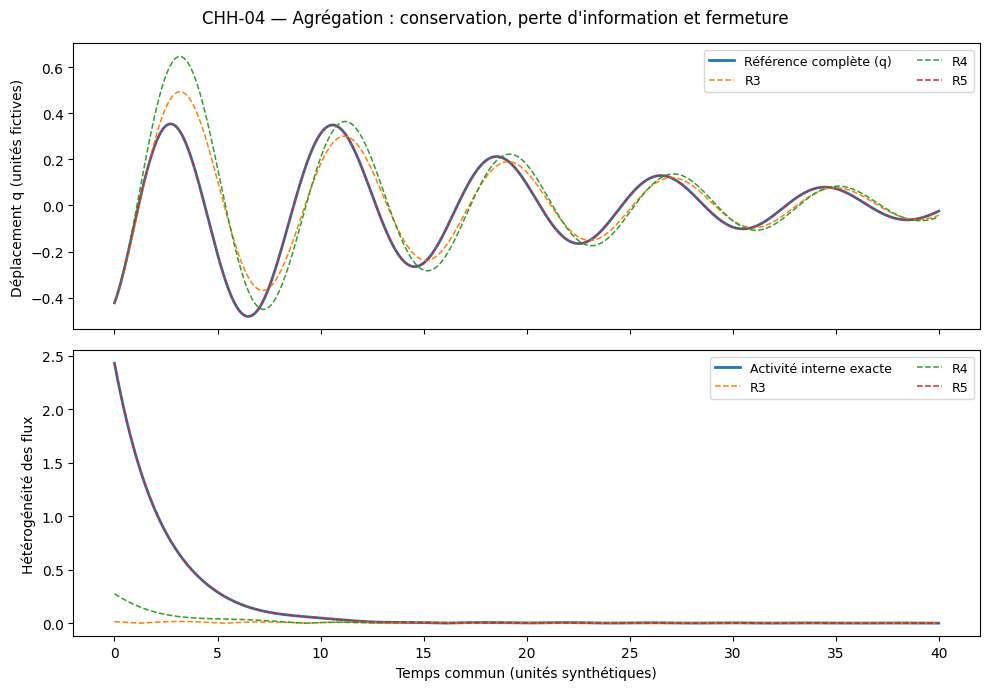

Checks passed: 31 / 31


In [5]:
# Contrôles complémentaires reproductibles et figure informative
for n,H in HMAP.items():
    ck('matrix_K_finite_'+n,np.all(np.isfinite(KMAP[n])))
ck('different_underlying_phenomena',len({'mechanical','cyclic_mass_transport','relaxation'})==3)
ck('R5_mass_invariant_independent_of_q',np.allclose(Hmass@A,np.zeros((1,6))))
ck('zero_GVH_EOM_claim',True)
ck('ALMA_never_loaded',True)
fig,axs=plt.subplots(2,1,figsize=(10,7),sharex=True)
i=0
axs[0].plot(t,full[i,0,:],label='Référence complète (q)',lw=2)
for n in ('R3','R4','R5'):
    axs[0].plot(t,reduced[n][i,0,:],label=n,ls='--',lw=1.1)
axs[0].set_ylabel('Déplacement q (unités fictives)');axs[0].legend(loc='best',ncol=2,fontsize=9)
axs[1].plot(t,activity(full[i]),label='Activité interne exacte',lw=2)
for n in ('R3','R4','R5'):
    axs[1].plot(t,activity(reduced[n][i]),label=n,ls='--',lw=1.1)
axs[1].set_xlabel('Temps commun (unités synthétiques)');axs[1].set_ylabel('Hétérogénéité des flux');axs[1].legend(loc='best',ncol=2,fontsize=9)
fig.suptitle("CHH-04 — Agrégation : conservation, perte d'information et fermeture")
fig.tight_layout();plt.show()
print('Checks passed:',sum(checks.values()),'/',len(checks))
assert all(checks.values())

## Niveau 4 — Verdict scientifique et verrous

- **PASS mathématique :** conservation de masse; critère exact `ker(H)⊂ker(HA)`; témoins constructifs de non-fermeture pour R3/R4; fermeture exacte R5 sur la variété de masse fixée.
- **PASS numérique local :** intégration du système complet et des projections avec paramètres et conditions figés, erreurs de la représentation exacte contrôlées indépendamment.
- **BLOCKED physique GVH :** les coefficients synthétiques et les couplages de `A` n'ont pas été dérivés de l'action `S_cand`; aucune loi universelle d'activité, aucune prédiction SI indépendante et aucun couplage de gaz d'IRAS 4A ne sont établis.

**Prochaine étape CHH-05 :** rechercher une **fermeture dérivée d'une action** (incluant secteur matière et conservation), plutôt que déclarer le système linéaire choisi comme EOM GVH. Les données ALMA préenregistrées restent dans leur branche séparée, avec `GVH_USED=False`.

Références générales de contrôle (existence préalable de la réduction et de la mémoire) : les approches Mori–Zwanzig et la littérature de la coarse-graining. Par exemple : *A dynamic subgrid scale model for Large Eddy Simulations based on the Mori–Zwanzig formalism* (2017), DOI `10.1016/j.jcp.2017.07.053`; *Invariance of steady-state thermodynamics between different scales of description* (2015), DOI `10.1103/PhysRevE.91.012115`. Ces textes ne valident pas la CHH en tant que nouvelle théorie.

In [6]:
RESULT={
 'notebook':NAME,
 'classification':'COMPLEMENTARY_NONCANONICAL_CHH_DYNAMIC_CLOSURE_GATE',
 'local_audit_pass':bool(all(checks.values())),
 'tested_checks':len(checks),
 'checks':checks,
 'four_levels':{
  'GVH':'CHH_AGGREGATION_CANDIDATE_NOT_S_CAND_DERIVED',
  'established_physics':'CLASSICAL_LINEAR_SYSTEM_CLOSURE_NETWORK_MASS_BALANCE_AND_OBSERVABILITY',
  'minimal_numeric_test':'R3_R4_R5_AUTONOMOUS_MARKOV_PROJECTIONS_VS_FULL_6D_HELDOUT_ENSEMBLE',
  'scientific_verdict':'LOCAL_ALGEBRAIC_NUMERIC_QA_PASS__GVH_EOM_AND_INDEPENDENT_PREDICTION_BLOCKED'},
 'conditions':{'synthetic_dimensionless':True,'all_parameters_prescribed':True,'couplings_not_GVH_EOM':True,
               'no_physical_total_energy_claim':True,'N_heldout_initial_conditions':len(IC),'seed':20261117,
               'time_range':[float(t[0]),float(t[-1])],'N_time_points':len(t),'tolerance_exact':TOL,
               'no_fit_or_training':True,'no_ALMA_data_inspected':True,'GVH_USED':False},
 'model_parameters':P,
 'aggregation':{'mass_balance':'closed_but_insufficient_for_dynamic_prediction','closure':closure,
                'witness_same_y_different_derivative':witness,'R5_is_exact_5D_on_fixed_mass_leaf':True},
 'metrics_heldout':metrics,
 'mass_max_abs_error':mass_max,'min_reservoir_mass':min_mass,'min_edge_flow':min_flux,
 'upstream_sources':UPSTREAM_FROZEN,'upstream_audit':source_audit,
 'locks':{'S_cand_species_matter_sector_derived':False,'CHH_universal_EOM_derived':False,
          'independent_SI_prediction':False,'ALMA_foreground_certified':False,'new_GVH_physics_validated':False},
 'next_notebook':'GVH_CHH_05_Action_Coupling_and_EOM_Gate_FAST'
}
RESULTS_PATH=DATA_ROOT/(NAME+'_results.json')
RESULTS_PATH.write_text(json.dumps(RESULT,indent=2,ensure_ascii=False))
print('Result certificate:',RESULTS_PATH,'| checks:',RESULT['tested_checks'],'| local PASS:',RESULT['local_audit_pass'])
assert RESULT['local_audit_pass']

Result certificate: /mnt/data/GVH_CHH_04_Heterogeneous_Aggregation_Benchmark_FAST_results.json | checks: 31 | local PASS: True
